# Notebook 01: Data Exploration, Keywords, and Claude Test

**Team:** Teenna Pachika and Johanna Garcia

**Project question:** What's driving negative Duolingo reviews, and do those complaints get better or worse after certain app updates?

This notebook covers:
1. Data exploration
2. Keyword analysis
3. Keyword-based complaint categories
4. A small Claude labeling test and our Phase 3 tool plan

In [1]:
# Importing libraries
import pandas as pd
import matplotlib.pyplot as plt

# Defining a function to load and prep the reviews
def load_reviews(path="../data/duolingo_reviews.csv"):
    """Load the reviews, turn the date column into real dates, and add a word count column."""
    df = pd.read_csv(path)
    df["at"] = pd.to_datetime(df["at"])
    df["content"] = df["content"].fillna("")
    df["n_words"] = df["content"].str.split().str.len()
    return df

# Defining a function to keep only negative reviews
def get_negative(df, max_stars=2):
    """Keep only the 1-2 star reviews."""
    return df[df["score"] <= max_stars].copy()

# Setting chart colors: red-orange = negative, gray = neutral, green = positive
NEG_COLOR = "#B5544C"
STAR_COLORS = ["#B5544C", "#B5544C", "#BFBFBF", "#7A9E7E", "#7A9E7E"]

# Loading the data
df = load_reviews()
neg = get_negative(df)

# Checking the counts
print("All reviews:", len(df))
print("Negative reviews (1-2 stars):", len(neg))

All reviews: 50000
Negative reviews (1-2 stars): 4147


## 1. Data Exploration

In [2]:
# Checking the size of the dataset
print("Rows and columns:", df.shape)

# Checking the column types
df.info()

# Checking for missing values
print("\nMissing values per column:")
print(df.isna().sum())

Rows and columns: (50000, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   reviewId              50000 non-null  object        
 1   content               50000 non-null  object        
 2   score                 50000 non-null  int64         
 3   thumbsUpCount         50000 non-null  int64         
 4   reviewCreatedVersion  45857 non-null  object        
 5   at                    50000 non-null  datetime64[ns]
 6   n_words               50000 non-null  int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 2.7+ MB

Missing values per column:
reviewId                   0
content                    0
score                      0
thumbsUpCount              0
reviewCreatedVersion    4143
at                         0
n_words                    0
dtype: int64


In [3]:
# Counting reviews with the exact same text
print("Duplicate reviews:", df.duplicated(subset="content").sum())

# Showing the 10 most common repeated reviews
print("\nMost common repeated reviews:")
print(df["content"].value_counts().head(10))

Duplicate reviews: 11787

Most common repeated reviews:
content
good         1565
nice          778
very good     451
nice app      264
good app      255
very nice     254
best          238
Good          184
I love it     180
good 👍        179
Name: count, dtype: int64


score
1     3049
2     1098
3     2322
4     6538
5    36993
Name: count, dtype: int64

% of reviews that are 1-2 stars: 8.3


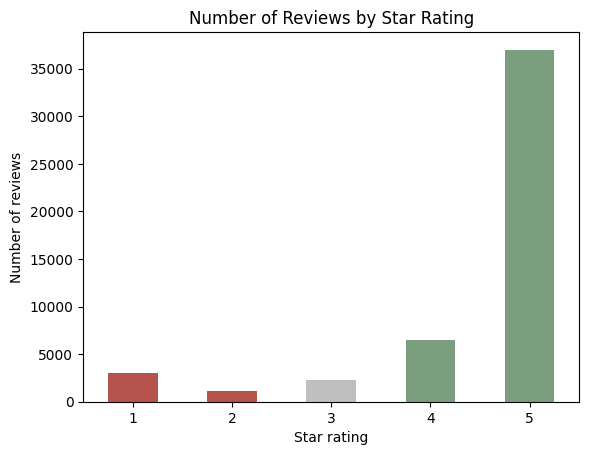

In [4]:
# Counting reviews for each star rating
star_counts = df["score"].value_counts().sort_index()
print(star_counts)
print("\n% of reviews that are 1-2 stars:", round(len(neg) / len(df) * 100, 1))

# Plotting the star rating distribution
star_counts.plot(kind="bar", color=STAR_COLORS)
plt.title("Number of Reviews by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

count    50000.000000
mean        11.449580
std         16.322078
min          1.000000
25%          2.000000
50%          6.000000
75%         13.000000
max        115.000000
Name: n_words, dtype: float64

Median words by star rating:
score
1    17.0
2    19.0
3     9.0
4     6.0
5     5.0
Name: n_words, dtype: float64


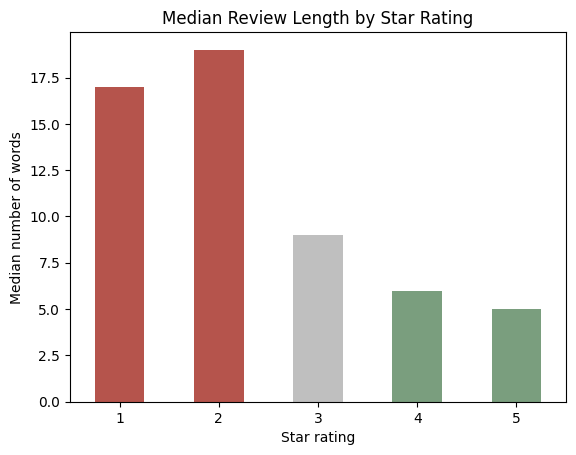

In [5]:
# Summarizing review length in words
print(df["n_words"].describe())

# Finding the median review length for each star rating
median_words = df.groupby("score")["n_words"].median()
print("\nMedian words by star rating:")
print(median_words)

# Plotting median review length by star rating
median_words.plot(kind="bar", color=STAR_COLORS)
plt.title("Median Review Length by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Median number of words")
plt.xticks(rotation=0)
plt.show()

In [6]:
# Showing 5 random negative reviews
pd.set_option("display.max_colwidth", None)
neg.sample(5, random_state=1)[["score", "content"]]

,score,content
38463,1,"Atrocious. spent 15 minutes repeating ""Yes, I, You, And"" and ran out of energy. useless for learning"
4368,1,it's not fair every country can use this app easily but WE ARE NOT because we are Iranian but we are not equal with government and this app shouldn't decide to make it worse for us when we need help to keep going
10063,2,"Discrimination against Iranian Citizens, Duo stopped giving services to Iranian Citizens like due language test, Duo dose not have learning Tibetan language but it has chinese. Duo dose not have listens for Kannada language. Duo listens for Hindi is very limited. needs a lot of improvement, otherwise I love this app."
11269,2,tough
38933,1,so bad


            all_reviews  negative  pct_negative
at                                             
2026-08-02         5198     393.0           7.6
2026-08-09         9206     719.0           7.8
2026-08-16         8744     640.0           7.3
2026-08-23         8166     622.0           7.6
2026-08-30         9079     902.0           9.9
2026-09-06         9606     871.0           9.1


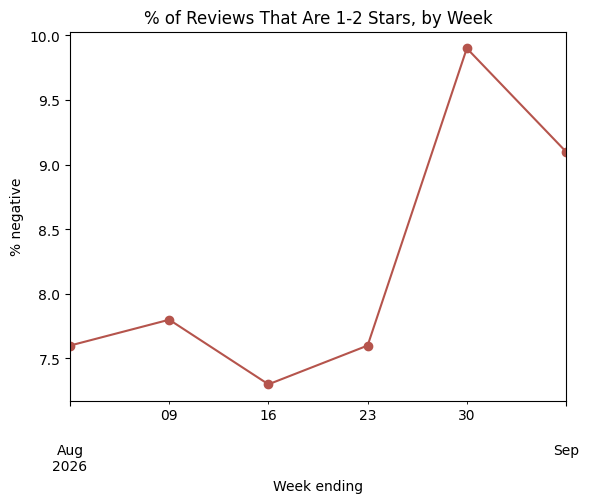

In [7]:
# Counting all reviews and negative reviews per week
weekly_all = df.set_index("at").resample("W").size()
weekly_neg = neg.set_index("at").resample("W").size()

# Calculating the % of reviews that are negative each week
weekly_pct = (weekly_neg / weekly_all * 100).round(1)
weekly_table = pd.DataFrame({"all_reviews": weekly_all, "negative": weekly_neg, "pct_negative": weekly_pct})
weekly_table = weekly_table[weekly_table["all_reviews"] > 100]   # dropping the near-empty last week
print(weekly_table)

# Plotting the % of negative reviews per week
weekly_table["pct_negative"].plot(marker="o", color=NEG_COLOR)
plt.title("% of Reviews That Are 1-2 Stars, by Week")
plt.xlabel("Week ending")
plt.ylabel("% negative")
plt.show()

### What we noticed

Only 8.3% of the reviews are 1-2 stars, but those reviews are a lot longer than the positive ones (around 17-19 words vs. 5 for 5-star reviews). We think that's actually good for our project, since the unhappy users are the ones explaining what went wrong, while most happy users just write "good" or "nice."

There are also way more 1-star reviews than 2-star (3,049 vs. 1,098). It seems like when people are annoyed with the app, they don't hold back.

About 11,800 reviews have the exact same text as another review, but when we looked, they're just short positive ones like "good" and "nice app," not spam. So we kept them, and they don't really affect the negative reviews we're focusing on.

Around 4,100 reviews (about 8%) are missing the app version, so we're going to use weeks to look at changes over time instead of app versions.

The part we found most interesting is the weekly trend. Negative reviews were about 7.5% of all reviews for most of August, then went up to 9.9% in the week ending Aug 30 and stayed above 9% the week after. It's only about a 2 point jump, but it's possible something changed around then, like an app update. In Phase 3 we want to figure out which complaints caused it.

When we read a few random negative reviews, some of them were about things we didn't expect, like users in Iran losing access and missing languages. A couple were also too short to tell what the problem was ("so bad," "tough"), so we probably won't be able to put every review into a category.

One thing to note: there's only one review after Sep 6, so our data really covers July 29 to Sep 6, 2026.

## 2. Keyword Analysis

In [8]:
# Importing tools for counting words
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

# Making a stopword list: common English words, plus "duolingo", "app", leftover pieces of contractions (don't, doesn't),
# and filler words that don't describe a complaint (just, like, use, want)
STOP_WORDS = list(ENGLISH_STOP_WORDS) + [
    "duolingo", "app",
    "don", "doesn", "didn", "isn",
    "just", "like", "use", "used", "using", "want",
    "don", "doesn", "didn", "isn", "ve"
]

# Defining a function to find the most common words and two-word phrases
def top_ngrams(texts, n=20):
    """Return the n most common words and two-word phrases in a list of reviews."""
    cv = CountVectorizer(stop_words=STOP_WORDS, ngram_range=(1, 2), min_df=5)
    counts = cv.fit_transform(texts)
    totals = counts.sum(axis=0).A1
    return pd.Series(totals, index=cv.get_feature_names_out()).sort_values(ascending=False).head(n)

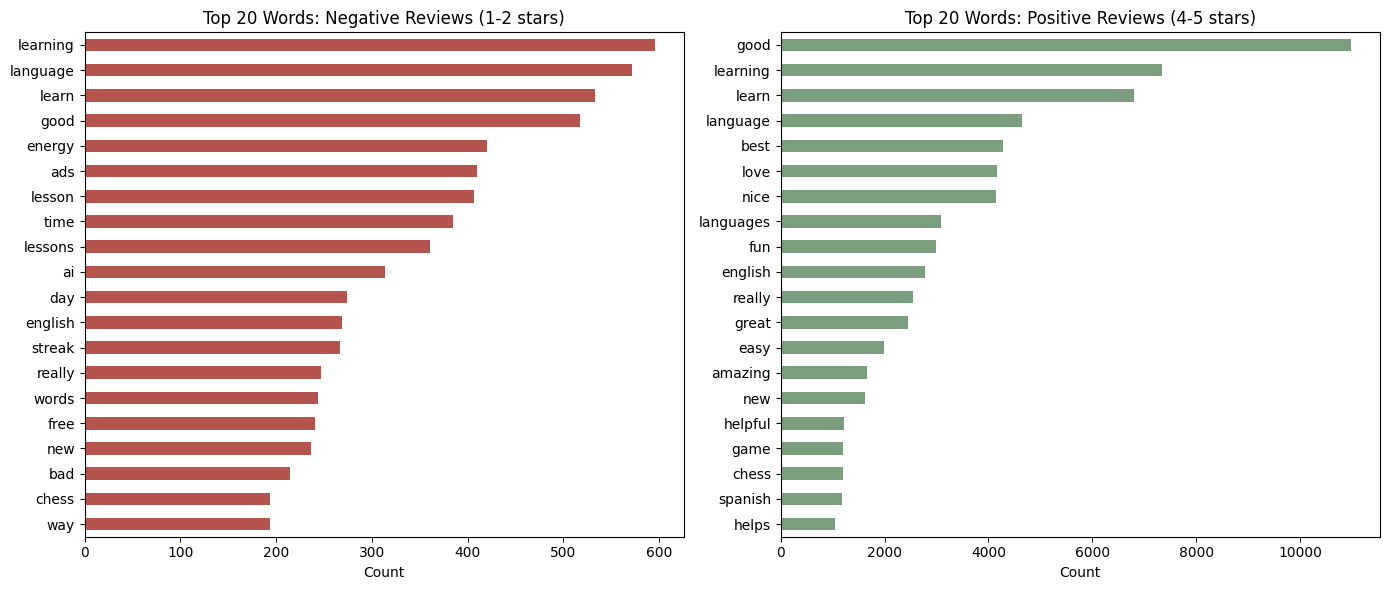

In [9]:
# Finding top words in negative and positive reviews
pos = df[df["score"] >= 4]
neg_words = top_ngrams(neg["content"])
pos_words = top_ngrams(pos["content"])

# Plotting them side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

neg_words.sort_values().plot(kind="barh", ax=axes[0], color=NEG_COLOR)
axes[0].set_title("Top 20 Words: Negative Reviews (1-2 stars)")
axes[0].set_xlabel("Count")

pos_words.sort_values().plot(kind="barh", ax=axes[1], color="#7A9E7E")
axes[1].set_title("Top 20 Words: Positive Reviews (4-5 stars)")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()

              neg_pct  pos_pct  gap
lesson            7.8      0.7  7.1
time              8.1      1.4  6.7
ads               7.5      0.9  6.7
energy            7.3      0.7  6.6
ai                6.5      0.2  6.3
lessons           7.2      1.3  5.9
streak            5.1      0.7  4.4
day               5.6      1.3  4.4
bad               4.7      0.4  4.3
subscription      3.9      0.2  3.7
annoying          3.8      0.3  3.6
update            3.6      0.2  3.4
money             3.7      0.2  3.4
pay               3.6      0.2  3.4
free              4.9      1.5  3.3
years             3.6      0.3  3.3
people            4.0      0.9  3.1
words             4.7      1.7  3.0
make              4.0      1.1  2.9
icon              3.0      0.1  2.9


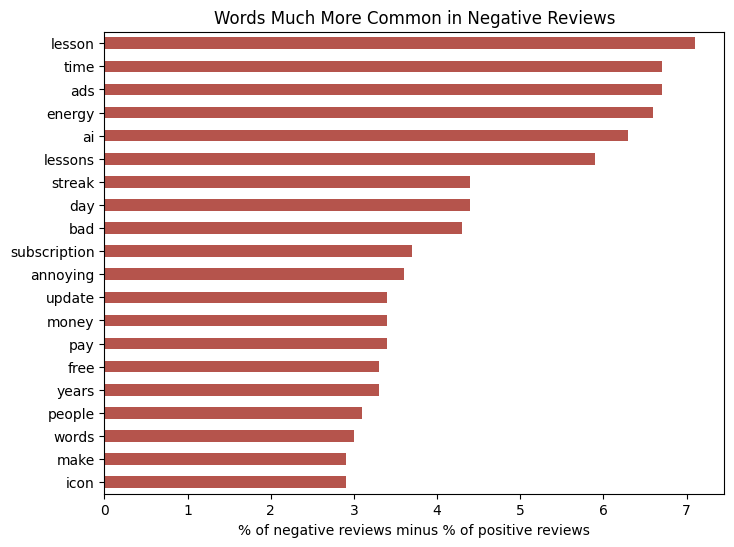

In [10]:
# Defining a function to find words that show up more in negative reviews than positive ones
def distinctive_words(neg_texts, pos_texts, n=20):
    """Compare the % of negative vs positive reviews that use each word, and return the biggest gaps."""
    cv = CountVectorizer(stop_words=STOP_WORDS, binary=True, min_df=20)
    cv.fit(pd.concat([neg_texts, pos_texts]))
    neg_pct = cv.transform(neg_texts).mean(axis=0).A1 * 100
    pos_pct = cv.transform(pos_texts).mean(axis=0).A1 * 100
    gaps = pd.DataFrame({"neg_pct": neg_pct, "pos_pct": pos_pct}, index=cv.get_feature_names_out())
    gaps["gap"] = gaps["neg_pct"] - gaps["pos_pct"]
    return gaps.sort_values("gap", ascending=False).head(n).round(1)

# Finding the words most typical of negative reviews
distinct = distinctive_words(neg["content"], pos["content"])
print(distinct)

# Plotting them
distinct["gap"].sort_values().plot(kind="barh", color=NEG_COLOR, figsize=(8, 6))
plt.title("Words Much More Common in Negative Reviews")
plt.xlabel("% of negative reviews minus % of positive reviews")
plt.show()

In [11]:
# Reading a few negative reviews that mention the surprise words
for word in ["ai", "icon"]:
    print(f"--- Reviews mentioning '{word}' ---")
    matches = neg[neg["content"].str.contains(rf"\b{word}\b", case=False)]
    for review in matches["content"].sample(5, random_state=1):
        print("-", review)
    print()

--- Reviews mentioning 'ai' ---
- they are scamming people for subscription, the ai conversations are really bad and the structure is very weak, not worth the 90 euros yearly scam
- App crashes constantly, overheats phone. When it works, it spams ads. I think it's gotten worse since they fired hundreds of people in favor of AI slop.
- Do NOT spend money on this app. There are a ton of flaws in a language or in Chess. Chess specifically is not setup to help you actually learn. And the AI part of the matches is setup so that you are 70% more likely to win. One win can net you +5 ELO and one loss can set you back -18 ELO. So 3 or 4 games to make back the loss. Over the past several years they have removed metrics, wonder why. They want you hooked in to get paid from sponsors. Better apps exist.
- Ai usage. Walked back that decision later. Evil AND spineless.
- Keeps getting worst with all the AI usage. It feels like a game, not like a useful teaching tool like it used to be.

--- Reviews 

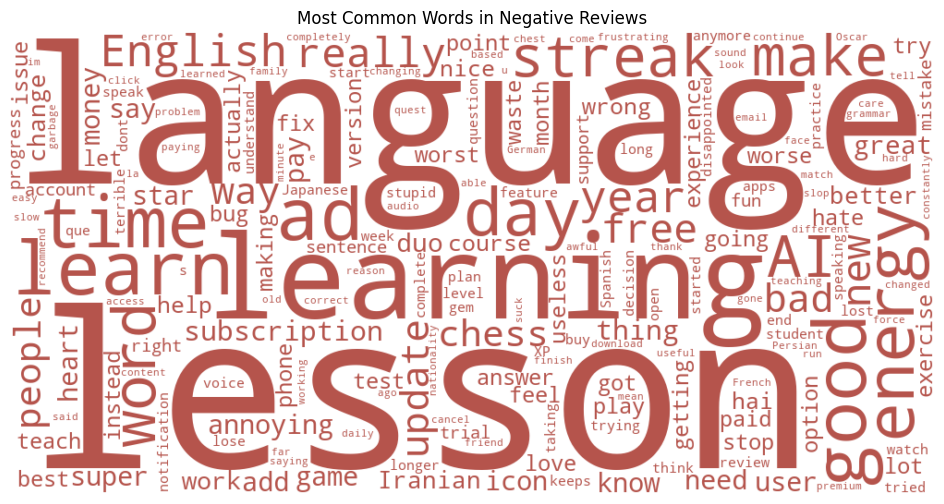

In [12]:
# Importing the word cloud tool and its built-in stopword list
from wordcloud import WordCloud, STOPWORDS

# Combining our stopwords with the word cloud's built-in ones (this removes contractions like don't, I'm)
cloud_stopwords = set(STOP_WORDS) | STOPWORDS

# Making a word cloud of the negative reviews, using our muted red for every word
neg_text = " ".join(neg["content"])
cloud = WordCloud(width=1000, height=500, background_color="white",
                  stopwords=cloud_stopwords, collocations=False,
                  color_func=lambda *args, **kwargs: NEG_COLOR).generate(neg_text)

# Showing the word cloud
plt.figure(figsize=(12, 6))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Common Words in Negative Reviews")
plt.show()

### What the keywords show

The top words for negative and positive reviews overlap a lot (words like "learning," "language," and "good" show up in both), so just counting words didn't tell us much. Comparing how often each word shows up in negative vs. positive reviews was a lot more useful.

The complaints we expected did show up. "Ads" is in 7.5% of negative reviews but only 0.9% of positive ones, "energy" (which replaced hearts) is 7.3% vs. 0.7%, and "streak" is 5.1% vs. 0.7%. Words about paying, like "subscription," "money," and "pay," each show up in about 3.7% of negative reviews but almost never in positive ones, which fits the free vs. paid frustration.

There were also a few things we didn't expect. "AI" shows up in 6.5% of negative reviews vs. 0.2% of positive ones. When we read some of them, people were upset about two things: the AI features themselves feeling low quality, and Duolingo replacing people with AI. "Icon" was another surprise. Duolingo changes the app icon to sad or weird owl faces to get people to come back, and a lot of users find it annoying.

"Update" also shows up way more in negative reviews (3.6% vs. 0.2%), which connects to our question about whether complaints change after app updates. "Lesson" and "time" are at the top too, so it seems like a lot of people are frustrated with how lessons work or how long they take.

For Phase 3, we think we should add AI and the icon/notification "guilt" features as their own complaint categories, since they came up a lot more than we expected.

## 3. Keyword-Based Complaint Categories

In [13]:
# Defining complaint categories and the keywords that point to each one
# (AI and icon/notifications were added because they came up in the keyword analysis)
CATEGORIES = {
    "energy_hearts": r"\benergy\b|\bhearts?\b|\blives\b",
    "streak": r"\bstreaks?\b",
    "ads": r"\bads?\b|\badverts?\b|\badvertisements?\b",
    "paywall": r"\bpremium\b|\bsuper\b|\bmax\b|\bsubscriptions?\b|\bpaid\b|\bpay\b|\bpaying\b|\bmoney\b",
    "ai": r"\bai\b",
    "icon_notifications": r"\bicons?\b|\bnotifications?\b",
    "bugs": r"\bbugs?\b|\bcrash|\bglitch|\bfreez|not working",
}

# Defining a function to tag each review with the categories it mentions
def tag_categories(reviews, categories=CATEGORIES):
    """Add a True/False column for each complaint category, plus one for reviews that match none."""
    reviews = reviews.copy()
    for name, pattern in categories.items():
        reviews[name] = reviews["content"].str.contains(pattern, case=False, regex=True)
    reviews["no_category"] = ~reviews[list(categories)].any(axis=1)
    return reviews

# Tagging the negative reviews
neg = tag_categories(neg)

paywall               14.4
ads                    9.4
energy_hearts          8.6
ai                     6.5
streak                 5.6
icon_notifications     4.8
bugs                   4.7
dtype: float64

% of negative reviews with no category: 61.8


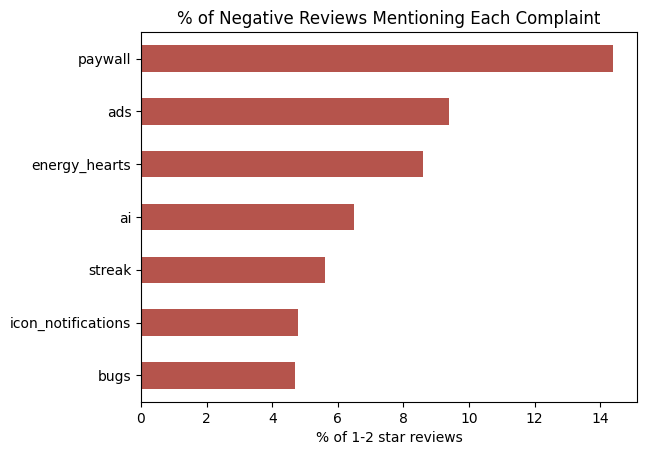

In [14]:
# Calculating the % of negative reviews in each category
cat_pct = (neg[list(CATEGORIES)].mean() * 100).round(1)
print(cat_pct.sort_values(ascending=False))
print("\n% of negative reviews with no category:", round(neg["no_category"].mean() * 100, 1))

# Plotting the % of negative reviews in each category
cat_pct.sort_values().plot(kind="barh", color=NEG_COLOR)
plt.title("% of Negative Reviews Mentioning Each Complaint")
plt.xlabel("% of 1-2 star reviews")
plt.show()

            energy_hearts  streak   ads  paywall   ai  icon_notifications  \
at                                                                          
2026-08-02            8.7     4.3   8.7     15.8  7.1                 2.3   
2026-08-09            9.5     6.1   8.6     15.6  4.9                 3.1   
2026-08-16            9.1     5.8  10.6     15.6  6.1                 2.3   
2026-08-23           10.9     6.3  13.5     15.9  7.7                 4.5   
2026-08-30            7.6     5.2   8.3     13.1  7.6                 5.1   
2026-09-06            6.9     5.6   7.6     12.4  5.7                 9.3   

            bugs  
at                
2026-08-02   4.1  
2026-08-09   5.6  
2026-08-16   5.3  
2026-08-23   4.8  
2026-08-30   4.7  
2026-09-06   3.8  


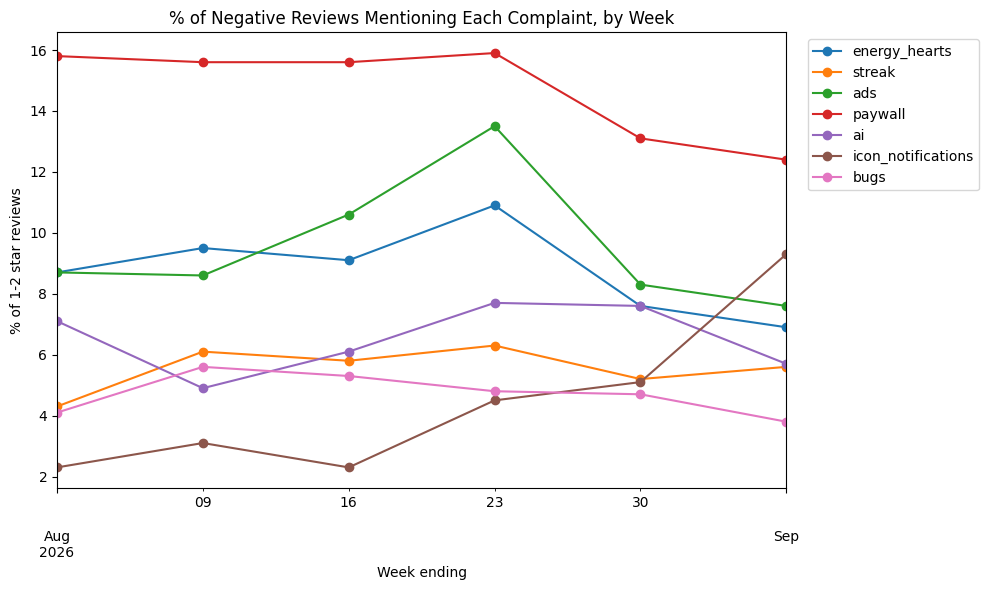

In [15]:
# Calculating the % of negative reviews in each category, by week
weekly_cats = (neg.set_index("at")[list(CATEGORIES)].resample("W").mean() * 100).round(1)
print(weekly_cats)

# Plotting how each complaint changes week to week
weekly_cats.plot(marker="o", figsize=(10, 6))
plt.title("% of Negative Reviews Mentioning Each Complaint, by Week")
plt.xlabel("Week ending")
plt.ylabel("% of 1-2 star reviews")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### What the complaint categories show

We tagged each negative review based on keywords for the complaints we expected, plus AI and the icon/notification stuff since those came up in the keyword analysis. A review can count for more than one category.

Paying is the biggest complaint. About 14% of negative reviews mention something like premium, subscription, or money. After that it's ads (9%) and energy/hearts (9%). AI, streaks, icon/notifications, and bugs are each around 5-7%.

The weekly chart was the most interesting part. Icon and notification complaints went from about 2-3% of negative reviews in early August to 9.3% in the week ending Sep 6. That's around the same time the overall share of negative reviews went up, so it's possible a change to the icon or notifications is part of what made people more annoyed. Ad complaints also peaked at 13.5% in the week ending Aug 23 and then dropped back down. We can't say for sure what caused these changes without knowing Duolingo's update dates, but they're the first things we'd want to look into in Phase 3.

The biggest limitation is that about 62% of negative reviews didn't match any of our keywords. Some are too short to tell ("so bad"), and some just describe the problem in different words (like "lost my 300 days" instead of "streak"). Keywords can also be wrong sometimes. For example, "super" is the name of Duolingo's paid plan, but someone could also write "super annoying." That's a big reason we want to use Claude in Phase 3, since it can read the full review instead of just matching words.